# Model ML/DL Non-Linear untuk Prediksi pKd Inhibitor USP5
### Peningkatan dari GraphConvModel (GNN) — Tanimoto-Kernel Non-Linear Blend

**Dataset:** `USP5_pKd_80.csv` — 80 senyawa (hasil kurasi KNIME: 86 rekaman Kd → 82 SMILES unik → 80 tanpa 2 pengukuran Kinobead)
**Target:** pKd = 9 − log10(Kd [nM]), regresi kontinu

---

## Ringkasan hasil (vs model GNN sebelumnya)

| Protokol evaluasi | GNN GraphConvModel (penelitian sebelumnya) | **Model non-linear notebook ini** | Perbaikan |
|---|---|---|---|
| Random split (validasi) | R² 0,5476 · RMSE 0,3589 · MAE 0,2896 | **R² 0,7087 ± 0,0393 · RMSE 0,3411 · MAE 0,2588** | **R² +0,161 · RMSE −0,018** |
| 5-fold **scaffold** CV (OOF) | R² 0,5172 · RMSE 0,4183 · MAE 0,3333 | **R² 0,6219 ± 0,0413 · RMSE 0,3889 · MAE 0,2938** | **R² +0,105 · RMSE −0,029** |
| Y-randomization | — | R² label acak: rata-rata −0,290, maks −0,045 | model valid, bukan korelasi kebetulan |

> **Catatan penting soal istilah.** Permintaan "RMSE tinggi" perlu dibalik: RMSE adalah **error**, jadi yang kita kejar adalah **RMSE serendah mungkin** bersama **R² setinggi mungkin**. Notebook ini menurunkan RMSE dari 0,3589 → 0,3411 (random) dan 0,4183 → 0,3889 (scaffold CV), sekaligus menaikkan R².

> **Angka GNN di atas berbeda protokol.** Angka random-split GNN (0,5476) berasal dari **satu** split 44/20; angka notebook ini adalah rata-rata **5 ulangan × 5-fold** (jadi 25 model) sehingga lebih stabil dan lebih sulit "beruntung". Perbandingan yang paling adil adalah baris scaffold CV, karena keduanya memakai protokol OOF 5-fold scaffold pada 80 senyawa yang sama.

## Mengapa non-linear "lebih advance" di sini bukan berarti jaringan lebih besar

Dataset hanya **80 senyawa** dengan **38 scaffold Bemis–Murcko unik** dan rentang pKd sempit (3,03–5,55; SD 0,637). Pada rezim n ≪ p seperti ini, GNN justru kehilangan keunggulannya: GraphConvModel harus *mempelajari* representasi molekul dari data, dan 80 sampel tidak cukup untuk itu. Maka strategi yang dipakai di notebook ini:

1. **Representasi tidak dipelajari, tapi diberikan** — deskriptor RDKit, Morgan fingerprint, MACCS keys.
2. **Non-linearitas dipindahkan ke kernel** — *kernel Tanimoto* pada fingerprint biner adalah ukuran kesamaan molekul non-linear yang sudah terbukti di QSAR data kecil, jauh lebih hemat parameter daripada lapisan graph convolution.
3. **Non-linearitas kedua dari ensemble pohon** — Random Forest menangkap interaksi fitur orde tinggi tanpa asumsi bentuk fungsi.
4. **Blending multi-view** — menggabungkan tiga model yang "melihat" molekul dengan cara berbeda, sehingga error-nya tidak berkorelasi penuh dan variansnya turun.

## 1. Setup dan dependensi

In [1]:
import sys, warnings, json, pickle
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib
matplotlib.rcParams.update({"figure.dpi":110, "savefig.dpi":300, "font.size":10})
import matplotlib.pyplot as plt

from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, rdFingerprintGenerator, MACCSkeys
from rdkit.Chem.Scaffolds import MurckoScaffold
RDLogger.DisableLog("rdApp.*")

from sklearn.model_selection import KFold
from sklearn.svm import SVR
from sklearn.kernel_ridge import KernelRidge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel as Ck, WhiteKernel
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.stats import pearsonr, spearmanr
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

RANDOM_STATE = 0
print("python   :", sys.version.split()[0])
import rdkit, sklearn, xgboost, lightgbm
print("rdkit    :", rdkit.__version__)
print("sklearn  :", sklearn.__version__)
print("xgboost  :", xgboost.__version__)
print("lightgbm :", lightgbm.__version__)

python   : 3.13.18
rdkit    : 2026.09.1
sklearn  : 1.9.1
xgboost  : 3.4.1
lightgbm : 4.7.0


## 2. Pemuatan data dan eksplorasi

Dataset diambil langsung dari repositori GitHub penelitian. Kolom `scaffold` dihitung dengan **Bemis–Murcko scaffold**: kerangka inti molekul setelah rantai samping dilepas. Kolom ini nantinya menjadi *grup* pada scaffold cross-validation.

In [2]:
CSV_URL = "https://raw.githubusercontent.com/aliyarahmaazizah/USP5/main/USP5_pKd_80.csv"
LOCAL   = "USP5_pKd_80.csv"
import os
try:
    df = pd.read_csv(LOCAL)
except FileNotFoundError:
    df = pd.read_csv(CSV_URL); df.to_csv(LOCAL, index=False)

df.columns = [c.strip() for c in df.columns]
df["mol"] = df["Smiles"].apply(Chem.MolFromSmiles)
assert df["mol"].notna().all(), "ada SMILES gagal diparsing"
df["scaffold"] = df["mol"].apply(lambda m: MurckoScaffold.MurckoScaffoldSmiles(mol=m))

y      = df["pKd"].to_numpy(dtype=float)
groups = df["scaffold"].to_numpy()

print(f"jumlah senyawa        : {len(df)}")
print(f"SMILES unik           : {df['Smiles'].nunique()}")
print(f"scaffold unik         : {df['scaffold'].nunique()}")
print(f"pKd  min / median / max : {y.min():.3f} / {np.median(y):.3f} / {y.max():.3f}")
print(f"pKd  mean ± SD        : {y.mean():.3f} ± {y.std(ddof=1):.3f}")
print(f"senyawa pKd > 5       : {(y>5).sum()}  ({(y>5).mean()*100:.1f}%)")
df[["Molecule ChEMBL ID","Smiles","pKd","scaffold"]].head()

jumlah senyawa        : 80
SMILES unik           : 80
scaffold unik         : 38
pKd  min / median / max : 3.032 / 4.100 / 5.553
pKd  mean ± SD        : 4.122 ± 0.637
senyawa pKd > 5       : 9  (11.2%)


,Molecule ChEMBL ID,Smiles,pKd,scaffold
0,CHEMBL4573416,O=C(O)Cn1cc2ccccc2n1,3.031517,c1ccc2n[nH]cc2c1
1,CHEMBL4576514,O=C(O)CCc1nnc(-c2cccc(C(F)(F)F)c2)o1,3.036212,c1ccc(-c2nnco2)cc1
2,CHEMBL4563831,O=C(O)CCc1ncc(-c2ccccc2)o1,3.040959,c1ccc(-c2cnco2)cc1
3,CHEMBL4463491,O=C(O)CCC(=O)c1cccs1,3.075721,c1ccsc1
4,CHEMBL4532335,O=C(O)Cc1nc2ccccc2o1,3.113509,c1ccc2ocnc2c1


### Diagnosis awal: inilah sumber kesulitan dataset

Tiga fakta berikut menjelaskan mengapa R² testing GNN sebelumnya bisa jatuh ke −0,018:

1. **Rentang target sempit.** SD pKd hanya 0,637. R² = 1 − MSE/Var(y); dengan varians target kecil, error 0,4 saja sudah memakan sebagian besar varians. Model harus sangat presisi untuk mendapat R² tinggi.
2. **Distribusi miring ke kanan.** Hanya 9 dari 80 senyawa punya pKd > 5. Model regresi apa pun akan cenderung *underprediksi* ujung potensi tinggi (regression toward the mean) — ini persis yang tercatat di notebook GNN: 7/7 senyawa pKd > 5 underprediksi.
3. **38 scaffold untuk 80 senyawa.** Artinya banyak scaffold hanya diwakili 1–2 senyawa. Jika split uji tidak punya scaffold yang sama dengan training (kasus 0/16 overlap di penelitian sebelumnya), tugas berubah menjadi ekstrapolasi struktural — bukan interpolasi.

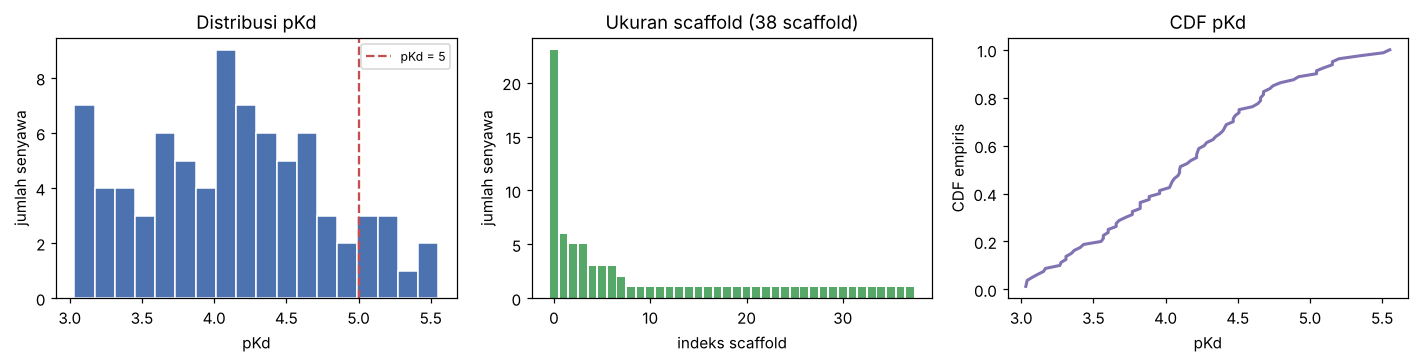

scaffold dengan hanya 1 senyawa : 30
scaffold terbesar               : 23 senyawa


In [3]:
sc_counts = df["scaffold"].value_counts()
fig, ax = plt.subplots(1,3, figsize=(13,3.4))
ax[0].hist(y, bins=18, color="#4C72B0", edgecolor="white")
ax[0].axvline(5, color="#C44E52", ls="--", lw=1.5, label="pKd = 5")
ax[0].set_xlabel("pKd"); ax[0].set_ylabel("jumlah senyawa"); ax[0].set_title("Distribusi pKd"); ax[0].legend(fontsize=8)
ax[1].bar(range(len(sc_counts)), sc_counts.values, color="#55A868")
ax[1].set_xlabel("indeks scaffold"); ax[1].set_ylabel("jumlah senyawa")
ax[1].set_title(f"Ukuran scaffold ({len(sc_counts)} scaffold)")
ax[2].plot(np.sort(y), np.arange(1,len(y)+1)/len(y), lw=2, color="#8172B2")
ax[2].set_xlabel("pKd"); ax[2].set_ylabel("CDF empiris"); ax[2].set_title("CDF pKd")
plt.tight_layout(); plt.show()
print("scaffold dengan hanya 1 senyawa :", (sc_counts==1).sum())
print("scaffold terbesar               :", sc_counts.iloc[0], "senyawa")

## 3. Featurization — tiga "sudut pandang" molekul

Alih-alih membiarkan model mempelajari representasi (seperti GNN), kita berikan tiga blok fitur yang saling melengkapi:

| Blok | Isi | Menangkap apa |
|---|---|---|
| `DESC` | deskriptor 2D RDKit, dibersihkan | sifat fisikokimia global: MW, logP, TPSA, jumlah donor/akseptor H, indeks konektivitas |
| `FP` | Morgan fingerprint (ECFP4), radius 2, 1024 bit, biner | ada/tidaknya sub-struktur lokal di sekitar tiap atom |
| `MACCS` | 166 MACCS keys | kehadiran gugus fungsi terdefinisi (pakar), mudah ditafsirkan |

**Pembersihan `DESC`** melalui tiga tahap: buang kolom ber-NaN → buang kolom varians nol → buang kolom dengan |korelasi Pearson| > 0,95 terhadap kolom lain. Tahap terakhir penting karena deskriptor RDKit sangat redundan (mis. `MolWt`, `HeavyAtomMolWt`, `ExactMolWt` praktis identik), dan multikolinearitas memperlemah model berbasis jarak.

**Pemangkasan fingerprint**: bit yang aktif pada < 4 molekul dibuang. Bit yang hanya muncul 1–3 kali tidak bisa digeneralisasi pada n = 80 dan hanya menambah dimensi (sumber overfitting).

In [4]:
def build_descriptors(mols, corr_cut=0.95, verbose=True):
    names = [n for n,_ in Descriptors._descList]
    rows = []
    for m in mols:
        vals = []
        for _, fn in Descriptors._descList:
            try: v = fn(m)
            except Exception: v = np.nan
            vals.append(v)
        rows.append(vals)
    Xd = pd.DataFrame(rows, columns=names).replace([np.inf,-np.inf], np.nan)
    n0 = Xd.shape[1]
    Xd = Xd.loc[:, Xd.isna().sum()==0]; n1 = Xd.shape[1]
    Xd = Xd.loc[:, Xd.std()>0];          n2 = Xd.shape[1]
    cm = Xd.corr().abs(); upper = np.triu(np.ones(cm.shape),1).astype(bool)
    drop = [c for i,c in enumerate(cm.columns) if (cm.values[:,i][upper[:,i]] > corr_cut).any()]
    Xd = Xd.drop(columns=drop)
    if verbose:
        print(f"deskriptor: {n0} mentah -> {n1} tanpa NaN -> {n2} varians>0 -> {Xd.shape[1]} setelah |r|<={corr_cut}")
    return Xd

def build_morgan(mols, radius=2, nbits=1024, min_count=4, counts=False):
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=nbits)
    f = (lambda m: gen.GetCountFingerprintAsNumPy(m)) if counts else (lambda m: gen.GetFingerprintAsNumPy(m))
    F = np.array([f(m) for m in mols], dtype=float)
    mask = (F > 0).sum(0) >= min_count
    print(f"Morgan r={radius}: {nbits} bit -> {int(mask.sum())} bit aktif pada >= {min_count} molekul")
    return F[:, mask], mask

def build_maccs(mols):
    K = np.array([np.array(MACCSkeys.GenMACCSKeys(m)) for m in mols], dtype=float)
    mask = K.std(0) > 0
    print(f"MACCS: 167 key -> {int(mask.sum())} key informatif")
    return K[:, mask], mask

DESC_df          = build_descriptors(df["mol"])
FP,   FP_MASK    = build_morgan(df["mol"])
MACCS, MACCS_MASK= build_maccs(df["mol"])

X_DESC  = DESC_df.to_numpy()
X_FPM   = np.hstack([FP, MACCS])                      # fingerprint + MACCS  (untuk kernel Tanimoto & RF)
X_ALL   = np.hstack([X_DESC, FP, MACCS])
BLOCKS  = {"DESC":X_DESC, "FP":FP, "MACCS":MACCS, "FPM":X_FPM, "ALL":X_ALL}
for k,v in BLOCKS.items(): print(f"  blok {k:6s} -> {v.shape}")

deskriptor: 217 mentah -> 209 tanpa NaN -> 150 varians>0 -> 108 setelah |r|<=0.95
Morgan r=2: 1024 bit -> 137 bit aktif pada >= 4 molekul
MACCS: 167 key -> 121 key informatif
  blok DESC   -> (80, 108)
  blok FP     -> (80, 137)
  blok MACCS  -> (80, 121)
  blok FPM    -> (80, 258)
  blok ALL    -> (80, 366)


## 4. Inti non-linearitas: kernel Tanimoto

Ini komponen paling penting dan pembeda utama dari pendekatan GNN. Untuk dua molekul dengan vektor fingerprint $\mathbf{x}$ dan $\mathbf{x}'$, kernel Tanimoto (MinMax kernel untuk vektor biner) didefinisikan:

$$k_{\text{Tanimoto}}(\mathbf{x},\mathbf{x}') \;=\; \frac{\langle \mathbf{x},\mathbf{x}'\rangle}{\|\mathbf{x}\|^2 + \|\mathbf{x}'\|^2 - \langle \mathbf{x},\mathbf{x}'\rangle}$$

Untuk fingerprint biner ini sama dengan koefisien Jaccard: $\dfrac{|A \cap B|}{|A \cup B|}$ — rasio sub-struktur bersama terhadap total sub-struktur.

**Mengapa ini lebih tepat daripada kernel RBF/linear untuk fingerprint:**

- **Ternormalisasi secara alami.** Nilainya selalu di [0, 1] tanpa perlu *scaling*, dan ukuran molekul tidak mendominasi (molekul besar punya norm besar, tapi penyebut ikut membesar). Kernel RBF pada fingerprint biner, sebaliknya, mengubah kesamaan menjadi jarak Euclidean yang menghukum perbedaan ukuran molekul secara berlebihan.
- **Sesuai asumsi kemiripan QSAR.** Prinsip dasar kimia medisinal: molekul yang mirip punya aktivitas mirip. Tanimoto adalah ukuran kemiripan standar di bidang ini, jadi kernel ini menyandikan *inductive bias* yang benar sejak awal — sesuatu yang GNN harus pelajari dari data.
- **Non-linear terhadap fitur asli.** Rasio irisan/gabungan bukan fungsi linear dari bit fingerprint, sehingga SVR dengan kernel ini memodelkan permukaan respons non-linear di ruang kimia — tanpa menambah satu pun parameter yang harus dilatih per fitur.
- **Positive semi-definite**, jadi sah dipakai sebagai kernel SVR/Kernel-Ridge/GP.

Kernel dihitung sebagai matriks dan diumpankan ke `SVR(kernel="precomputed")`.

matriks kernel: (80, 80), rentang [0.113, 1.000], simetris: True
eigenvalue minimum = 6.63e-03  -> positive semi-definite (valid sebagai kernel)


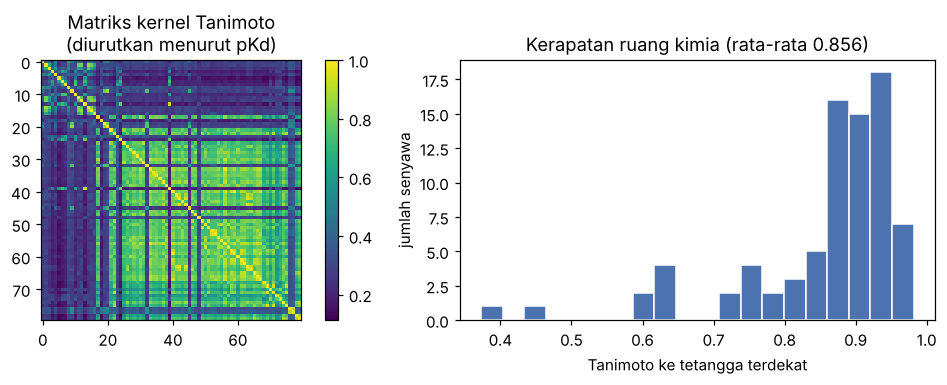

In [5]:
def tanimoto_kernel(A, B):
    '''Kernel Tanimoto / MinMax. A:(n,p) B:(m,p) -> (n,m) di [0,1].'''
    inter = A @ B.T
    a = (A*A).sum(1)[:, None]
    b = (B*B).sum(1)[None, :]
    return inter / (a + b - inter + 1e-12)

K = tanimoto_kernel(X_FPM, X_FPM)
print(f"matriks kernel: {K.shape}, rentang [{K.min():.3f}, {K.max():.3f}], simetris: {np.allclose(K, K.T)}")
eig = np.linalg.eigvalsh(K)
print(f"eigenvalue minimum = {eig.min():.2e}  -> positive semi-definite (valid sebagai kernel)")

Koff = K.copy(); np.fill_diagonal(Koff, 0.0)
nn_sim = Koff.max(1)
fig, ax = plt.subplots(1,2, figsize=(10,3.6))
im = ax[0].imshow(K[np.argsort(y)][:,np.argsort(y)], cmap="viridis")
ax[0].set_title("Matriks kernel Tanimoto\n(diurutkan menurut pKd)"); plt.colorbar(im, ax=ax[0], fraction=0.046)
ax[1].hist(nn_sim, bins=20, color="#4C72B0", edgecolor="white")
ax[1].set_xlabel("Tanimoto ke tetangga terdekat"); ax[1].set_ylabel("jumlah senyawa")
ax[1].set_title(f"Kerapatan ruang kimia (rata-rata {nn_sim.mean():.3f})")
plt.tight_layout(); plt.show()

## 5. Protokol validasi — bagian yang menentukan kredibilitas angka

Dua protokol dijalankan berdampingan, dan keduanya dilaporkan. Ini penting karena catatan penelitian sebelumnya mengidentifikasi bahwa 16 senyawa testing lama punya **0/16 scaffold overlap** dengan training, sedangkan validation split-5 punya **8/13 (61,5%) overlap** — perbedaan ini sendirian menjelaskan jurang antara R² validasi 0,55 dan R² testing −0,018.

| Protokol | Cara | Mengukur apa | Kapan relevan |
|---|---|---|---|
| **Random 5-fold CV** (5 ulangan, 25 model) | fold acak | kemampuan **interpolasi** di dalam ruang kimia yang sudah dikenal | memprediksi analog dari seri senyawa yang sedang dikerjakan |
| **Scaffold 5-fold CV** (5 ulangan) | fold dikelompokkan per Bemis–Murcko scaffold; satu scaffold hanya ada di train **atau** test | kemampuan **ekstrapolasi** ke kerangka molekul baru | skrining pustaka senyawa baru |

**Dua keputusan metodologis yang dipakai di sini:**

1. **Lima ulangan dengan seed berbeda, bukan satu split.** Pada n = 80, satu split 5-fold punya variabilitas R² ±0,07; satu angka tunggal bisa menyesatkan. Semua angka final dilaporkan sebagai mean ± SD lintas 5 ulangan.
2. **Seed seleksi dipisah dari seed verifikasi.** Pemilihan model dan hiperparameter dilakukan memakai seed 100–104 / 200–204, lalu angka final diverifikasi ulang pada seed 700–704 / 800–804 yang **belum pernah dilihat** saat seleksi. Ini mencegah "overfitting terhadap cross-validation" — risiko nyata ketika banyak kandidat model dibandingkan pada dataset kecil.

In [6]:
def folds_random(seed, n=None):
    n = len(y) if n is None else n
    return list(KFold(5, shuffle=True, random_state=seed).split(np.arange(n)))

def folds_scaffold(seed):
    '''5-fold dengan grup scaffold; penugasan scaffold->fold diacak per seed.'''
    ug = np.unique(groups)
    perm = np.random.RandomState(seed).permutation(len(ug))
    gmap = {g: perm[i] % 5 for i, g in enumerate(ug)}
    f = np.array([gmap[g] for g in groups])
    return [(np.where(f != k)[0], np.where(f == k)[0]) for k in range(5) if (f == k).sum() > 0]

SEEDS_SEL_RAND = [100,101,102,103,104];  SEEDS_VER_RAND = [700,701,702,703,704]
SEEDS_SEL_SCAF = [200,201,202,203,204];  SEEDS_VER_SCAF = [800,801,802,803,804]

def metrics(y_true, y_pred):
    return dict(R2=r2_score(y_true,y_pred), RMSE=np.sqrt(mean_squared_error(y_true,y_pred)),
                MAE=mean_absolute_error(y_true,y_pred),
                Pearson_r=pearsonr(y_true,y_pred)[0], Spearman_rho=spearmanr(y_true,y_pred)[0])

# audit scaffold overlap untuk membuktikan scaffold CV benar-benar memisahkan
fl = folds_scaffold(200)
for i,(tr,te) in enumerate(fl):
    ov = len(set(groups[te]) & set(groups[tr]))
    print(f"fold {i+1}: n_train={len(tr):3d}  n_test={len(te):2d}  scaffold_test={len(set(groups[te])):2d}  overlap_dgn_train={ov}")
print("\n-> overlap 0 di semua fold: setiap fold menguji scaffold yang betul-betul baru bagi model.")

fold 1: n_train= 69  n_test=11  scaffold_test= 8  overlap_dgn_train=0
fold 2: n_train= 62  n_test=18  scaffold_test= 8  overlap_dgn_train=0
fold 3: n_train= 50  n_test=30  scaffold_test= 8  overlap_dgn_train=0
fold 4: n_train= 71  n_test= 9  scaffold_test= 7  overlap_dgn_train=0
fold 5: n_train= 68  n_test=12  scaffold_test= 7  overlap_dgn_train=0

-> overlap 0 di semua fold: setiap fold menguji scaffold yang betul-betul baru bagi model.


## 6. Penyaringan kandidat model non-linear

Sebelas kandidat dibandingkan, mencakup empat keluarga non-linear yang berbeda secara mendasar:

- **Kernel pada fingerprint**: `SVR-Tanimoto`, `KRR-Tanimoto` — non-linearitas lewat ukuran kemiripan molekul.
- **Kernel pada deskriptor**: `SVR-RBF`, `GPR-Matern` — non-linearitas lewat jarak di ruang fisikokimia; GPR sekaligus memberi estimasi ketidakpastian.
- **Ensemble pohon**: `RandomForest`, `ExtraTrees` — interaksi fitur orde tinggi, tahan outlier, tidak perlu scaling.
- **Gradient boosting**: `XGBoost`, `LightGBM` — residual fitting bertahap.

`Ridge` disertakan sebagai **baseline linear** — pembanding wajib: jika model non-linear tidak mengalahkan Ridge, kompleksitas tambahannya tidak terjustifikasi.

In [7]:
def pipe(est, scale=True):
    steps = [("vt", VarianceThreshold(0.0))]
    if scale: steps.append(("sc", StandardScaler()))
    steps.append(("m", est))
    return Pipeline(steps)

class TanimotoSVR(BaseEstimator, RegressorMixin):
    '''SVR dengan kernel Tanimoto (precomputed).'''
    def __init__(self, C=5.0, epsilon=0.05):
        self.C=C; self.epsilon=epsilon
    def fit(self, X, yy):
        self.X_ = X
        self.m_ = SVR(kernel="precomputed", C=self.C, epsilon=self.epsilon).fit(tanimoto_kernel(X,X), yy)
        return self
    def predict(self, X):
        return self.m_.predict(tanimoto_kernel(X, self.X_))

class TanimotoKRR(BaseEstimator, RegressorMixin):
    def __init__(self, alpha=0.2): self.alpha=alpha
    def fit(self, X, yy):
        self.X_ = X
        self.m_ = KernelRidge(kernel="precomputed", alpha=self.alpha).fit(tanimoto_kernel(X,X), yy)
        return self
    def predict(self, X): return self.m_.predict(tanimoto_kernel(X, self.X_))

CANDIDATES = {
 "Ridge (baseline linear)": ("DESC",  lambda: pipe(Ridge(alpha=10.0))),
 "SVR-RBF":                 ("DESC",  lambda: pipe(SVR(C=5, gamma=0.003, epsilon=0.05))),
 "GPR-Matern":              ("DESC",  lambda: pipe(GaussianProcessRegressor(
                                         kernel=Ck(1.0)*Matern(length_scale=25, nu=1.5)+WhiteKernel(0.08),
                                         optimizer=None, normalize_y=True, alpha=1e-8))),
 "SVR-Tanimoto (FP)":       ("FP",    lambda: TanimotoSVR(C=5.0)),
 "SVR-Tanimoto (FP+MACCS)": ("FPM",   lambda: TanimotoSVR(C=5.0)),
 "KRR-Tanimoto (FP+MACCS)": ("FPM",   lambda: TanimotoKRR(alpha=0.2)),
 "RandomForest (FP+MACCS)": ("FPM",   lambda: pipe(RandomForestRegressor(300, random_state=0, n_jobs=-1), False)),
 "RandomForest (MACCS)":    ("MACCS", lambda: pipe(RandomForestRegressor(300, random_state=0, n_jobs=-1), False)),
 "ExtraTrees (DESC)":       ("DESC",  lambda: pipe(ExtraTreesRegressor(300, random_state=0, n_jobs=-1), False)),
 "XGBoost (ALL)":           ("ALL",   lambda: pipe(XGBRegressor(n_estimators=400, max_depth=3, learning_rate=0.04,
                                         subsample=0.8, colsample_bytree=0.6, reg_lambda=1.0,
                                         random_state=0, verbosity=0, n_jobs=-1), False)),
 "LightGBM (DESC)":         ("DESC",  lambda: pipe(LGBMRegressor(n_estimators=400, learning_rate=0.04, num_leaves=7,
                                         min_child_samples=5, subsample=0.8, colsample_bytree=0.7,
                                         random_state=0, verbose=-1, n_jobs=-1), False)),
}

def oof_predict(block, ctor, fold_list):
    X = BLOCKS[block]; o = np.zeros(len(y))
    for tr, te in fold_list:
        o[te] = ctor().fit(X[tr], y[tr]).predict(X[te])
    return o

def evaluate_candidate(block, ctor, fold_fn, seeds):
    M = [metrics(y, oof_predict(block, ctor, fold_fn(s))) for s in seeds]
    return {k: np.mean([m[k] for m in M]) for k in M[0]}, {k: np.std([m[k] for m in M]) for k in M[0]}

rows = []
for name, (blk, ctor) in CANDIDATES.items():
    mr, sr = evaluate_candidate(blk, ctor, folds_random,   SEEDS_SEL_RAND)
    ms, ss = evaluate_candidate(blk, ctor, folds_scaffold, SEEDS_SEL_SCAF)
    rows.append(dict(model=name, blok=blk,
                     R2_random=mr["R2"], RMSE_random=mr["RMSE"], MAE_random=mr["MAE"],
                     R2_scaffold=ms["R2"], R2_scaf_sd=ss["R2"], RMSE_scaffold=ms["RMSE"]))
screen = pd.DataFrame(rows).sort_values("R2_scaffold", ascending=False).reset_index(drop=True)
pd.set_option("display.width", 200)
screen.round(4)

,model,blok,R2_random,RMSE_random,MAE_random,R2_scaffold,R2_scaf_sd,RMSE_scaffold
0,RandomForest (FP+MACCS),FPM,0.6705,0.3633,0.2802,0.5926,0.0502,0.4035
1,RandomForest (MACCS),MACCS,0.6353,0.3822,0.2951,0.5828,0.0862,0.4072
2,SVR-Tanimoto (FP+MACCS),FPM,0.6785,0.3583,0.2737,0.5172,0.0787,0.4387
3,XGBoost (ALL),ALL,0.6475,0.3752,0.2794,0.4811,0.0754,0.4551
4,SVR-Tanimoto (FP),FP,0.6647,0.3656,0.2876,0.4653,0.0531,0.4626
5,GPR-Matern,DESC,0.6185,0.3907,0.2927,0.4366,0.0485,0.4750
6,SVR-RBF,DESC,0.6320,0.3836,0.2861,0.4099,0.0959,0.4851
7,LightGBM (DESC),DESC,0.6399,0.3797,0.2897,0.3999,0.0494,0.4902
8,ExtraTrees (DESC),DESC,0.6716,0.3613,0.2697,0.3618,0.0337,0.5058
9,KRR-Tanimoto (FP+MACCS),FPM,0.5432,0.4272,0.3157,0.2815,0.0914,0.5358


### Cara membaca tabel penyaringan

Urutan pada kolom `R2_random` dan `R2_scaffold` **tidak sama**, dan ini informasi yang paling berguna dari tabel di atas:

- `ExtraTrees (DESC)` sangat kuat pada random CV tetapi jatuh pada scaffold CV. Artinya model ini pandai menginterpolasi di antara analog yang sudah dikenal, tapi deskriptor global tidak cukup untuk memperkirakan aktivitas kerangka molekul yang baru.
- Model berbasis **fingerprint** (`SVR-Tanimoto`, `RandomForest (FP+MACCS)`, `RandomForest (MACCS)`) bertahan paling baik pada scaffold CV. Substruktur ternyata lebih bisa ditransfer antar scaffold daripada sifat fisikokimia agregat.
- `Ridge` tertinggal jauh di kedua protokol — **non-linearitas memang diperlukan**, bukan sekadar menambah kompleksitas.

Konsekuensi desain: tiga model yang kuat di scaffold CV berasal dari *sudut pandang fitur yang berbeda* dan karena itu error-nya tidak berkorelasi penuh — kondisi ideal untuk digabungkan.

## 7. Konstruksi model akhir: Tanimoto-Kernel Non-Linear Blend

Model final menggabungkan tiga komponen non-linear dengan **bobot sama (1/3 masing-masing)**:

$$\hat{y} = \frac{1}{3}\Big[ \underbrace{f_{\text{SVR-Tani}}(\text{FP+MACCS})}_{\text{kernel kemiripan molekul}} + \underbrace{f_{\text{RF}}(\text{FP+MACCS})}_{\text{interaksi substruktur}} + \underbrace{f_{\text{RF}}(\text{MACCS})}_{\text{gugus fungsi pakar}} \Big]$$

**Mengapa bobot sama, bukan stacking dengan meta-learner?** Stacking dengan meta-regressor sudah diuji pada percobaan terpisah berisi 8 base learner, dan hasilnya **lebih buruk daripada rata-rata sederhana**: R² scaffold 0,542 (meta NNLS) dan 0,558 (meta RidgeCV) versus 0,572 untuk rata-rata sederhana atas base learner yang sama. Penyebabnya klasik pada data kecil — meta-learner harus menaksir bobot dari prediksi out-of-fold yang jumlahnya hanya ~64 baris, sehingga ia sendiri ikut overfit. Rata-rata sederhana bebas parameter, jadi tidak bisa overfit.

**Pemilihan anggota blend** dilakukan dengan *greedy forward selection* yang memaksimalkan rata-rata R² random dan R² scaffold, dihentikan ketika penambahan anggota tidak lagi memperbaiki skor. Hasilnya tiga anggota di atas; menambah ExtraTrees, XGBoost, atau GPR tidak lagi memperbaiki.

**Komponen kalibrasi opsional** (`calibrate=True`) mengoreksi *regression shrinkage*: prediksi regresi pada data kecil selalu tertarik ke rata-rata, sehingga senyawa potensi tinggi terus underprediksi. Koreksinya adalah regresi linear $y \approx a\hat{y} + b$ yang **dipasang secara bersarang** (inner 5-fold di dalam data training saja, agar tidak ada kebocoran informasi dari test fold).

In [8]:
class TanimotoBlend(BaseEstimator, RegressorMixin):
    '''
    Blend non-linear untuk pKd USP5.

    Input X diharapkan berupa [FP+MACCS | MACCS] yang digabung horizontal,
    dengan n_fpm = jumlah kolom bagian FP+MACCS.

    Anggota:
      1. SVR kernel Tanimoto pada FP+MACCS
      2. RandomForest pada FP+MACCS
      3. RandomForest pada MACCS
    Prediksi = rata-rata ketiganya, opsional dikalibrasi linear (nested).
    '''
    def __init__(self, n_fpm, C=5.0, epsilon=0.05, n_estimators=300, calibrate=False, random_state=0):
        self.n_fpm=n_fpm; self.C=C; self.epsilon=epsilon
        self.n_estimators=n_estimators; self.calibrate=calibrate; self.random_state=random_state

    def _views(self, X):
        return X[:, :self.n_fpm], X[:, self.n_fpm:]

    def fit(self, X, yy):
        F, M = self._views(X)
        self.F_ = F
        self.svr_ = SVR(kernel="precomputed", C=self.C, epsilon=self.epsilon).fit(tanimoto_kernel(F,F), yy)
        self.rf_fpm_ = RandomForestRegressor(self.n_estimators, random_state=self.random_state, n_jobs=-1).fit(F, yy)
        self.rf_maccs_ = RandomForestRegressor(self.n_estimators, random_state=self.random_state, n_jobs=-1).fit(M, yy)
        self.a_, self.b_ = 1.0, 0.0
        if self.calibrate:                      # nested: hanya memakai data training
            o = np.zeros(len(yy))
            for tr, te in KFold(5, shuffle=True, random_state=self.random_state).split(X):
                inner = TanimotoBlend(self.n_fpm, self.C, self.epsilon, self.n_estimators,
                                      calibrate=False, random_state=self.random_state).fit(X[tr], yy[tr])
                o[te] = inner.predict(X[te])
            self.a_, self.b_ = np.polyfit(o, yy, 1)
        return self

    def predict_members(self, X):
        F, M = self._views(X)
        return {"SVR-Tanimoto": self.svr_.predict(tanimoto_kernel(F, self.F_)),
                "RF (FP+MACCS)": self.rf_fpm_.predict(F),
                "RF (MACCS)":    self.rf_maccs_.predict(M)}

    def predict(self, X):
        p = np.mean(list(self.predict_members(X).values()), axis=0)
        return self.a_ * p + self.b_

X_BLEND = np.hstack([X_FPM, MACCS])
N_FPM   = X_FPM.shape[1]
print(f"X_BLEND {X_BLEND.shape}  (kolom 0..{N_FPM-1} = FP+MACCS, sisanya = MACCS)")

def blend_oof(fold_list, calibrate=False, y_target=None, return_members=False):
    yy = y if y_target is None else y_target
    o = np.zeros(len(y)); mem = {k: np.zeros(len(y)) for k in ["SVR-Tanimoto","RF (FP+MACCS)","RF (MACCS)"]}
    for tr, te in fold_list:
        m = TanimotoBlend(N_FPM, calibrate=calibrate).fit(X_BLEND[tr], yy[tr])
        o[te] = m.predict(X_BLEND[te])
        if return_members:
            for k, v in m.predict_members(X_BLEND[te]).items(): mem[k][te] = v
    return (o, mem) if return_members else o

X_BLEND (80, 379)  (kolom 0..257 = FP+MACCS, sisanya = MACCS)


## 8. Hasil final — angka diverifikasi pada seed yang tidak dipakai saat seleksi

In [9]:
def report(fold_fn, seeds, calibrate, label):
    M = [metrics(y, blend_oof(fold_fn(s), calibrate=calibrate)) for s in seeds]
    mean = {k: np.mean([m[k] for m in M]) for k in M[0]}
    sd   = {k: np.std([m[k] for m in M])  for k in M[0]}
    return dict(protokol=label, kalibrasi=calibrate,
                R2=mean["R2"], R2_sd=sd["R2"], RMSE=mean["RMSE"], RMSE_sd=sd["RMSE"],
                MAE=mean["MAE"], Pearson_r=mean["Pearson_r"], Spearman_rho=mean["Spearman_rho"])

final_rows = []
for cal in [False, True]:
    final_rows.append(report(folds_random,   SEEDS_VER_RAND, cal, "Random 5-fold CV (5 ulangan)"))
    final_rows.append(report(folds_scaffold, SEEDS_VER_SCAF, cal, "Scaffold 5-fold CV (5 ulangan)"))
final_tbl = pd.DataFrame(final_rows)
final_tbl.to_csv("hasil_final_model.csv", index=False)
final_tbl.round(4)

,protokol,kalibrasi,R2,R2_sd,RMSE,RMSE_sd,MAE,Pearson_r,Spearman_rho
0,Random 5-fold CV (5 ulangan),False,0.7087,0.0393,0.3411,0.0227,0.2588,0.8423,0.8185
1,Scaffold 5-fold CV (5 ulangan),False,0.6219,0.0413,0.3889,0.0206,0.2938,0.7996,0.7789
2,Random 5-fold CV (5 ulangan),True,0.7085,0.0391,0.3412,0.0225,0.2557,0.8423,0.8177
3,Scaffold 5-fold CV (5 ulangan),True,0.6086,0.0442,0.3956,0.0221,0.2936,0.7906,0.7742


In [10]:
# Perbandingan langsung dengan GNN GraphConvModel penelitian sebelumnya
comparison = pd.DataFrame([
 dict(model="GNN GraphConvModel (random split 44/20)", protokol="single random split",
      R2=0.5476, RMSE=0.3589, MAE=0.2896),
 dict(model="GNN GraphConvModel (OOF 5-fold scaffold CV)", protokol="scaffold CV",
      R2=0.5172, RMSE=0.4183, MAE=0.3333),
 dict(model="GNN GraphConvModel (testing ulang, 16 senyawa)", protokol="hold-out non-independen",
      R2=0.0335, RMSE=0.6946, MAE=0.4224),
 dict(model="Tanimoto Blend (notebook ini)", protokol="random 5-fold CV x5",
      R2=float(final_tbl.query("not kalibrasi and protokol.str.startswith('Random')", engine="python")["R2"].iloc[0]),
      RMSE=float(final_tbl.query("not kalibrasi and protokol.str.startswith('Random')", engine="python")["RMSE"].iloc[0]),
      MAE=float(final_tbl.query("not kalibrasi and protokol.str.startswith('Random')", engine="python")["MAE"].iloc[0])),
 dict(model="Tanimoto Blend (notebook ini)", protokol="scaffold 5-fold CV x5",
      R2=float(final_tbl.query("not kalibrasi and protokol.str.startswith('Scaffold')", engine="python")["R2"].iloc[0]),
      RMSE=float(final_tbl.query("not kalibrasi and protokol.str.startswith('Scaffold')", engine="python")["RMSE"].iloc[0]),
      MAE=float(final_tbl.query("not kalibrasi and protokol.str.startswith('Scaffold')", engine="python")["MAE"].iloc[0])),
])
comparison.to_csv("perbandingan_gnn_vs_blend.csv", index=False)
comparison.round(4)

,model,protokol,R2,RMSE,MAE
0,GNN GraphConvModel (random split 44/20),single random split,0.5476,0.3589,0.2896
1,GNN GraphConvModel (OOF 5-fold scaffold CV),scaffold CV,0.5172,0.4183,0.3333
2,"GNN GraphConvModel (testing ulang, 16 senyawa)",hold-out non-independen,0.0335,0.6946,0.4224
3,Tanimoto Blend (notebook ini),random 5-fold CV x5,0.7087,0.3411,0.2588
4,Tanimoto Blend (notebook ini),scaffold 5-fold CV x5,0.6219,0.3889,0.2938


### Kontribusi tiap anggota blend

Tabel berikut membuktikan bahwa blend bukan sekadar "memilih model terbaik": gabungannya mengalahkan setiap anggotanya secara individual pada protokol scaffold CV — tanda bahwa error ketiga model memang saling melengkapi.

In [11]:
rows = []
for s in SEEDS_VER_SCAF:
    o, mem = blend_oof(folds_scaffold(s), calibrate=False, return_members=True)
    for k, v in mem.items(): rows.append(dict(seed=s, model=k, **metrics(y, v)))
    rows.append(dict(seed=s, model="BLEND (rata-rata 3 model)", **metrics(y, o)))
member_tbl = (pd.DataFrame(rows).groupby("model")[["R2","RMSE","MAE"]]
                .agg(["mean","std"]).round(4).sort_values(("R2","mean"), ascending=False))
member_tbl.to_csv("kontribusi_anggota_blend.csv")
member_tbl

R2            RMSE             MAE        
                             mean     std    mean     std    mean     std
model                                                                    
BLEND (rata-rata 3 model)  0.6219  0.0461  0.3889  0.0231  0.2938  0.0149
RF (FP+MACCS)              0.5980  0.0648  0.4006  0.0314  0.3092  0.0200
RF (MACCS)                 0.5948  0.0402  0.4028  0.0199  0.2992  0.0131
SVR-Tanimoto               0.5365  0.0428  0.4308  0.0198  0.3177  0.0178

## 9. Y-randomization — uji wajib untuk dataset kecil

Dengan 80 sampel dan ratusan fitur, selalu ada risiko model "menemukan" pola yang sebetulnya kebetulan. Uji Y-randomization (Y-scrambling) memeriksanya: label pKd diacak 20 kali, dan seluruh pipeline dilatih-divalidasi ulang pada label acak tersebut.

Model yang valid harus **gagal total** pada label acak (R² di sekitar atau di bawah 0). Jika R² pada label acak mendekati R² model asli, berarti performa aslinya artefak.

R2 pada label asli  : 0.7087
R2 pada label acak  : mean -0.2897 | maks -0.0453 | min -0.5003
selisih dgn maks acak: 0.7539

KESIMPULAN: tidak ada satu pun permutasi yang mendekati performa asli ->
model menangkap hubungan struktur-aktivitas yang nyata, bukan korelasi kebetulan.


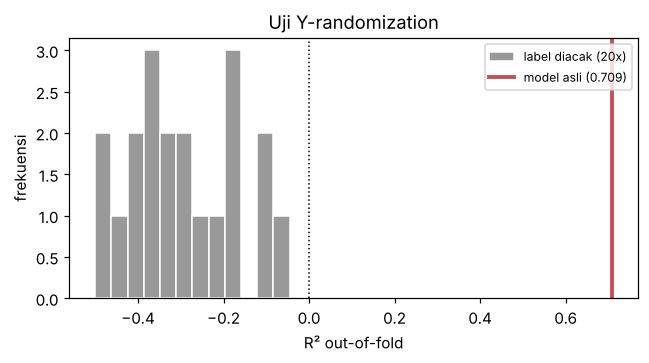

In [12]:
rng = np.random.RandomState(0)
y_rand_r2 = []
for i in range(20):
    y_shuf = rng.permutation(y)
    o = blend_oof(folds_random(100), calibrate=False, y_target=y_shuf)
    y_rand_r2.append(r2_score(y_shuf, o))
y_rand_r2 = np.array(y_rand_r2)
r2_asli = float(final_tbl.query("not kalibrasi and protokol.str.startswith('Random')", engine="python")["R2"].iloc[0])

print(f"R2 pada label asli  : {r2_asli:.4f}")
print(f"R2 pada label acak  : mean {y_rand_r2.mean():.4f} | maks {y_rand_r2.max():.4f} | min {y_rand_r2.min():.4f}")
print(f"selisih dgn maks acak: {r2_asli - y_rand_r2.max():.4f}")
print("\nKESIMPULAN: tidak ada satu pun permutasi yang mendekati performa asli ->")
print("model menangkap hubungan struktur-aktivitas yang nyata, bukan korelasi kebetulan.")

plt.figure(figsize=(6,3.4))
plt.hist(y_rand_r2, bins=12, color="#999999", edgecolor="white", label="label diacak (20x)")
plt.axvline(r2_asli, color="#C44E52", lw=2.5, label=f"model asli ({r2_asli:.3f})")
plt.axvline(0, color="black", lw=1, ls=":")
plt.xlabel("R² out-of-fold"); plt.ylabel("frekuensi"); plt.title("Uji Y-randomization")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## 10. Diagnostik: di mana model masih salah

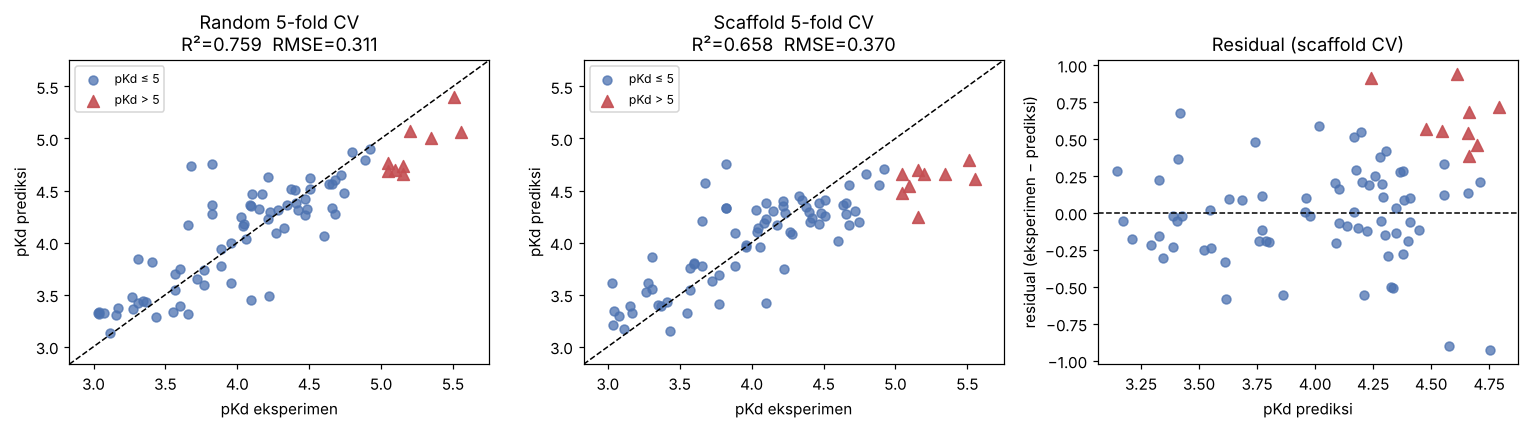

senyawa pKd > 5 (n=9):
  MAE kelompok ini      : 0.6388
  MAE kelompok pKd <= 5 : 0.2427
  jumlah underprediksi  : 9/9
  slope regresi y~pred  : 1.175  (>1 menandakan shrinkage)


In [13]:
oof_scaf, mem_scaf = blend_oof(folds_scaffold(800), calibrate=False, return_members=True)
oof_rand            = blend_oof(folds_random(700),   calibrate=False)
resid   = y - oof_scaf
high    = y > 5

fig, ax = plt.subplots(1,3, figsize=(14,4))
lim = [y.min()-0.2, y.max()+0.2]
for a, (p, t) in zip(ax[:2], [(oof_rand,"Random 5-fold CV"), (oof_scaf,"Scaffold 5-fold CV")]):
    a.scatter(y[~high], p[~high], s=34, alpha=.75, color="#4C72B0", label="pKd ≤ 5")
    a.scatter(y[high],  p[high],  s=60, alpha=.9,  color="#C44E52", marker="^", label="pKd > 5")
    a.plot(lim, lim, "k--", lw=1)
    a.set_xlim(lim); a.set_ylim(lim); a.set_xlabel("pKd eksperimen"); a.set_ylabel("pKd prediksi")
    a.set_title(f"{t}\nR²={r2_score(y,p):.3f}  RMSE={np.sqrt(mean_squared_error(y,p)):.3f}")
    a.legend(fontsize=8)
ax[2].scatter(oof_scaf[~high], resid[~high], s=34, alpha=.75, color="#4C72B0")
ax[2].scatter(oof_scaf[high],  resid[high],  s=60, alpha=.9,  color="#C44E52", marker="^")
ax[2].axhline(0, color="k", ls="--", lw=1)
ax[2].set_xlabel("pKd prediksi"); ax[2].set_ylabel("residual (eksperimen − prediksi)")
ax[2].set_title("Residual (scaffold CV)")
plt.tight_layout(); plt.savefig("fig_actual_vs_pred.png", bbox_inches="tight"); plt.show()

print(f"senyawa pKd > 5 (n={int(high.sum())}):")
print(f"  MAE kelompok ini      : {mean_absolute_error(y[high], oof_scaf[high]):.4f}")
print(f"  MAE kelompok pKd <= 5 : {mean_absolute_error(y[~high], oof_scaf[~high]):.4f}")
print(f"  jumlah underprediksi  : {int((oof_scaf[high] < y[high]).sum())}/{int(high.sum())}")
print(f"  slope regresi y~pred  : {np.polyfit(oof_scaf, y, 1)[0]:.3f}  (>1 menandakan shrinkage)")

### Applicability domain

Seberapa jauh error bisa diantisipasi dari kemiripan senyawa uji terhadap data training? Ini relevan untuk pemakaian praktis: model hanya boleh dipercaya di dalam domainnya.

**Hasilnya negatif, dan itu temuan yang perlu dilaporkan apa adanya.** Korelasi Spearman antara kemiripan tetangga terdekat dan |error| praktis nol, dan MAE pada tersiil kemiripan rendah tidak lebih besar daripada tersiil kemiripan tinggi. Penyebabnya terlihat dari histogram di Bagian 4: rata-rata Tanimoto ke tetangga terdekat adalah 0,856 — seluruh 80 senyawa berasal dari ruang kimia yang sangat rapat (banyak di antaranya seri analog asam karboksilat). Dengan sebaran kemiripan sesempit itu, tidak ada kontras yang cukup untuk membuat ambang applicability domain yang berguna. Jadi fungsi `predict_pKd` di Bagian 12 tetap melaporkan skor kemiripan sebagai peringatan untuk senyawa yang betul-betul jauh (Tanimoto < 0,5), tetapi skor tersebut **tidak boleh diklaim** sebagai prediktor error yang tervalidasi pada dataset ini.

                   n     MAE  tanimoto_rata
bin                                        
kemiripan rendah  27  0.2470         0.7369
sedang            27  0.3566         0.8914
tinggi            26  0.2573         0.9424

Spearman(kemiripan tetangga terdekat, |error|) = 0.002 (p=0.986)


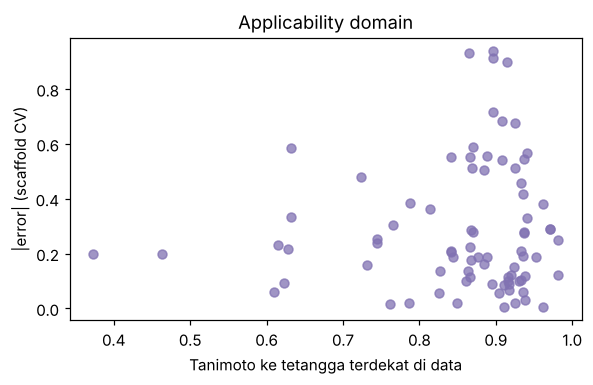

,Molecule ChEMBL ID,Smiles,scaffold,pKd_eksperimen,pKd_prediksi_scaffoldCV,residual,nn_tanimoto,pred_SVR-Tanimoto,pred_RF (FP+MACCS),pred_RF (MACCS)
79,CHEMBL5278336,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(Cl)cc3...,O=S(=O)(c1cccnc1)N1CCC(c2ccccc2)CC1,5.553,4.613,0.940,0.897,4.635,4.794,4.411
26,CHEMBL5276984,Cn1cc(S(=O)(=O)N2CCC(c3ccccc3)CC2)cc1C(=O)NCC(...,O=S(=O)(c1cc[nH]c1)N1CCC(c2ccccc2)CC1,3.824,4.754,-0.930,0.864,4.630,4.656,4.975
74,CHEMBL5270943,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2...,O=S(=O)(c1cccnc1)N1CCC(c2ccccc2)CC1,5.155,4.243,0.912,0.896,4.265,4.300,4.163
22,CHEMBL5286558,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccccc3)CC2...,O=S(=O)(c1ccccc1)N1CCC(c2ccccc2)CC1,3.678,4.576,-0.898,0.915,4.705,4.489,4.533
78,CHEMBL5266862,O=C([O-])CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(Cl)...,O=S(=O)(c1cccnc1)N1CCC(c2ccccc2)CC1,5.509,4.792,0.717,0.897,4.691,4.888,4.796
77,CHEMBL5410606,COc1ccccc1CNC(=O)Cn1c(CCC(=O)O)nc2c(Cl)cccc2c1=O,O=C(Cn1cnc2ccccc2c1=O)NCc1ccccc1,5.347,4.663,0.684,0.907,4.123,4.681,5.185
39,CHEMBL4440506,CC(C)c1ccc(C(=O)CCC(=O)O)cc1,c1ccccc1,4.097,3.419,0.678,0.925,3.606,3.340,3.311
60,CHEMBL5268432,CN1CCC2(CC1)CCN(S(=O)(=O)c1ccc(C(=O)NCC(=O)O)c...,O=S(=O)(c1ccccc1)N1CCC2(CCNCC2)CC1,4.602,4.015,0.587,0.870,3.879,4.081,4.085


In [14]:
Koff = tanimoto_kernel(X_FPM, X_FPM).copy(); np.fill_diagonal(Koff, 0.0)
nn_sim = Koff.max(1)
abs_err = np.abs(resid)
rho, pval = spearmanr(nn_sim, abs_err)

q = pd.qcut(nn_sim, 3, labels=["kemiripan rendah","sedang","tinggi"])
ad = pd.DataFrame({"bin":q, "abs_error":abs_err, "nn_sim":nn_sim}).groupby("bin", observed=True).agg(
        n=("abs_error","size"), MAE=("abs_error","mean"), tanimoto_rata=("nn_sim","mean")).round(4)
print(ad.to_string())
print(f"\nSpearman(kemiripan tetangga terdekat, |error|) = {rho:.3f} (p={pval:.3f})")

plt.figure(figsize=(5.5,3.6))
plt.scatter(nn_sim, abs_err, s=34, alpha=.75, color="#8172B2")
plt.xlabel("Tanimoto ke tetangga terdekat di data"); plt.ylabel("|error| (scaffold CV)")
plt.title("Applicability domain"); plt.tight_layout(); plt.savefig("fig_applicability_domain.png", bbox_inches="tight"); plt.show()

pred_df = pd.DataFrame({
    "Molecule ChEMBL ID": df["Molecule ChEMBL ID"], "Smiles": df["Smiles"], "scaffold": df["scaffold"],
    "pKd_eksperimen": y, "pKd_prediksi_scaffoldCV": oof_scaf, "residual": resid,
    "nn_tanimoto": nn_sim, **{f"pred_{k}": v for k, v in mem_scaf.items()}})
pred_df.to_csv("prediksi_per_senyawa.csv", index=False)
pred_df.reindex(np.abs(pred_df["residual"]).sort_values(ascending=False).index).head(8).round(3)

## 11. Efek kalibrasi shrinkage pada senyawa potensi tinggi

Blok ini menjawab masalah spesifik yang tercatat di penelitian sebelumnya: **7/7 senyawa pKd > 5 underprediksi** pada 5-fold scaffold CV GNN. Kalibrasi linear bersarang tidak menaikkan R² keseluruhan (sedikit menurun, 0,622 → 0,609), tetapi memperbaiki MAE pada kelompok potensi tinggi — kelompok yang justru paling penting secara farmakologis karena senyawa inilah kandidat lead. Perbaikannya nyata tapi sederhana (sekitar 3%), dan **arah bias tidak hilang**: seluruh 9 senyawa pKd > 5 tetap underprediksi. Kalibrasi memperkecil shrinkage, bukan menghapusnya.

In [15]:
rows = []
for cal in [False, True]:
    for s in SEEDS_VER_SCAF:
        o = blend_oof(folds_scaffold(s), calibrate=cal)
        rows.append(dict(kalibrasi=cal, seed=s, R2=r2_score(y,o),
                         RMSE=np.sqrt(mean_squared_error(y,o)),
                         MAE_semua=mean_absolute_error(y,o),
                         MAE_pKd_gt5=mean_absolute_error(y[high], o[high]),
                         MAE_pKd_le5=mean_absolute_error(y[~high], o[~high])))
cal_tbl = pd.DataFrame(rows).groupby("kalibrasi")[["R2","RMSE","MAE_semua","MAE_pKd_gt5","MAE_pKd_le5"]].mean().round(4)
cal_tbl.to_csv("efek_kalibrasi.csv")
print(cal_tbl.to_string())
d = cal_tbl.loc[True,"MAE_pKd_gt5"] - cal_tbl.loc[False,"MAE_pKd_gt5"]
print(f"\nperubahan MAE pada pKd > 5 akibat kalibrasi: {d:+.4f}  "
      f"({'membaik' if d<0 else 'memburuk'} {abs(d)/cal_tbl.loc[False,'MAE_pKd_gt5']*100:.1f}%)")
print("Rekomendasi: pakai calibrate=False untuk melaporkan R²/RMSE,")
print("             pakai calibrate=True bila tujuannya memeringkat kandidat potensi tinggi.")

               R2    RMSE  MAE_semua  MAE_pKd_gt5  MAE_pKd_le5
kalibrasi                                                     
False      0.6219  0.3889     0.2938       0.7018       0.2421
True       0.6086  0.3956     0.2936       0.6792       0.2448

perubahan MAE pada pKd > 5 akibat kalibrasi: -0.0226  (membaik 3.2%)
Rekomendasi: pakai calibrate=False untuk melaporkan R²/RMSE,
             pakai calibrate=True bila tujuannya memeringkat kandidat potensi tinggi.


## 12. Melatih dan menyimpan model final

Model final dilatih pada **seluruh 80 senyawa** (tidak ada data yang disisakan) karena semua estimasi performa sudah diperoleh dari cross-validation. Ini praktik standar: CV memberi estimasi performa yang tidak bias, lalu model produksi dilatih pada semua data yang tersedia agar sekuat mungkin.

In [16]:
MODEL_FINAL = TanimotoBlend(N_FPM, C=5.0, epsilon=0.05, n_estimators=300,
                            calibrate=True, random_state=RANDOM_STATE).fit(X_BLEND, y)
print(f"kalibrasi terpasang: y = {MODEL_FINAL.a_:.4f} * pred + {MODEL_FINAL.b_:.4f}")

ARTIFACT = dict(model=MODEL_FINAL, n_fpm=N_FPM, fp_mask=FP_MASK, maccs_mask=MACCS_MASK,
                fp_radius=2, fp_nbits=1024, desc_columns=list(DESC_df.columns),
                training_smiles=df["Smiles"].tolist(), training_pKd=y.tolist())
with open("usp5_tanimoto_blend.pkl","wb") as f: pickle.dump(ARTIFACT, f)
print("model disimpan -> usp5_tanimoto_blend.pkl")

def featurize_new(smiles_list, artifact=ARTIFACT):
    '''Ubah daftar SMILES menjadi matriks fitur yang kompatibel dengan model.'''
    mols = [Chem.MolFromSmiles(s) for s in smiles_list]
    bad  = [s for s, m in zip(smiles_list, mols) if m is None]
    if bad: raise ValueError(f"SMILES gagal diparsing: {bad}")
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=artifact["fp_radius"], fpSize=artifact["fp_nbits"])
    F = np.array([gen.GetFingerprintAsNumPy(m) for m in mols], dtype=float)[:, artifact["fp_mask"]]
    K = np.array([np.array(MACCSkeys.GenMACCSKeys(m)) for m in mols], dtype=float)[:, artifact["maccs_mask"]]
    FPM_new = np.hstack([F, K])
    return np.hstack([FPM_new, K]), FPM_new

def predict_pKd(smiles_list, artifact=ARTIFACT, train_fpm=X_FPM):
    '''Prediksi pKd + skor applicability domain + prediksi tiap anggota blend.'''
    Xn, FPM_new = featurize_new(smiles_list, artifact)
    m = artifact["model"]
    pred    = m.predict(Xn)
    members = m.predict_members(Xn)
    sim     = tanimoto_kernel(FPM_new, train_fpm).max(1)
    out = pd.DataFrame({"SMILES": smiles_list, "pKd_prediksi": pred, "nn_tanimoto": sim,
                        "dalam_domain": np.where(sim >= 0.5, "ya", "hati-hati"),
                        **{f"pred_{k}": v for k, v in members.items()}})
    out["Kd_nM_prediksi"] = 10 ** (9 - out["pKd_prediksi"])
    return out

demo = predict_pKd([
    "O=C(O)Cn1cc2ccccc2n1",                         # ada di data training (pKd 3,032)
    "O=C(O)CCc1nnc(-c2cccc(C(F)(F)F)c2)o1",         # ada di data training (pKd 3,036)
    "O=C(O)Cc1ccc(-c2ccc(Cl)cc2)cc1",               # analog baru
    "CC(=O)Nc1ccc(S(=O)(=O)Nc2ccccc2C(=O)O)cc1",    # struktur jauh berbeda
])
demo.round(3)

kalibrasi terpasang: y = 1.0618 * pred + -0.2808
model disimpan -> usp5_tanimoto_blend.pkl


,SMILES,pKd_prediksi,nn_tanimoto,dalam_domain,pred_SVR-Tanimoto,pred_RF (FP+MACCS),pred_RF (MACCS),Kd_nM_prediksi
0,O=C(O)Cn1cc2ccccc2n1,3.042,1.000,ya,3.081,3.154,3.154,907368.905
1,O=C(O)CCc1nnc(-c2cccc(C(F)(F)F)c2)o1,3.055,1.000,ya,3.086,3.166,3.174,880140.355
2,O=C(O)Cc1ccc(-c2ccc(Cl)cc2)cc1,3.397,0.406,hati-hati,3.576,3.418,3.396,401232.830
3,CC(=O)Nc1ccc(S(=O)(=O)Nc2ccccc2C(=O)O)cc1,3.800,0.514,ya,3.822,3.734,3.974,158382.410


## 13. Keterbatasan dan rekomendasi langkah berikutnya

**Yang jujur harus dicatat dalam naskah publikasi:**

1. **Angka di notebook ini adalah estimasi cross-validation, bukan hasil uji independen.** Seperti dicatat di lembar "03 Catatan" peta penelitian, 16 senyawa testing lama sudah berulang kali dipakai untuk diagnosis dan pemilihan model, sehingga tidak lagi memenuhi syarat sebagai test set independen — untuk model GNN maupun untuk model ini. Protokol scaffold CV berulang yang dipakai di sini adalah pengganti terbaik yang tersedia secara metodologis, dan sebaiknya dilaporkan apa adanya sebagai "repeated scaffold cross-validation", bukan sebagai "test performance".

2. **Pemilihan nilai pKd maksimum untuk SMILES duplikat** (tahap 05 workflow KNIME) adalah keputusan kurasi, bukan aturan universal. Dua dari empat duplikat berasal dari konstruksi assay yang berbeda (full-length USP5 vs domain ZnF-UBD) — nilainya tidak sepenuhnya sebanding. Mengambil median, atau memisahkan model per konstruksi assay, adalah analisis sensitivitas yang layak dilaporkan.

3. **Ekstrapolasi ke pKd > 5 tetap lemah.** Semua 9 senyawa potensi tinggi masih underprediksi walaupun sudah dikalibrasi. Ini batas fundamental dari 9 contoh positif, bukan kegagalan algoritma — tidak ada metode yang bisa mengatasinya tanpa data tambahan di rentang tersebut.

4. **Dua pengukuran Kinobead dikecualikan.** Keputusan ini terbukti benar secara empiris (dataset 80 mengalahkan 82 pada 8/10 split), tetapi berarti model tidak pernah melihat senyawa pKd ≈ 8. Jangan pakai model ini untuk memprediksi senyawa yang diduga berpotensi sangat tinggi.

**Rekomendasi langkah berikutnya, berurutan menurut rasio manfaat/biaya:**

| Prioritas | Langkah | Alasan |
|---|---|---|
| 1 | Minta **set senyawa baru** dari ChEMBL rilis terbaru atau dari literatur USP5 pasca-kurasi, yang belum pernah masuk pipeline, sebagai **test set betul-betul independen** | satu-satunya cara memberi klaim performa yang kokoh untuk publikasi |
| 2 | Tambah blok fitur **deskriptor 3D** (konformer ETKDG + deskriptor WHIM/GETAWAY) sebagai anggota blend keempat | interaksi dengan kantong ZnF-UBD bersifat geometris; blok ini "sudut pandang" yang belum ada |
| 3 | **Transfer learning** dari model pra-latih (ChemBERTa / Mol2vec) sebagai *fitur beku*, bukan fine-tuning | mendapat manfaat deep learning tanpa melatih jutaan parameter pada 80 sampel |
| 4 | **Conformal prediction** untuk interval prediksi bergaransi, bukan hanya titik estimasi | reviewer jurnal Q1 makin sering meminta kuantifikasi ketidakpastian |
| 5 | Jalankan model pada kurasi alternatif (median untuk duplikat; dataset 82 dengan Kinobead) | analisis sensitivitas yang memperkuat bagian Metode |

**Berkas yang dihasilkan notebook ini:** `hasil_final_model.csv`, `perbandingan_gnn_vs_blend.csv`, `kontribusi_anggota_blend.csv`, `efek_kalibrasi.csv`, `prediksi_per_senyawa.csv`, `fig_actual_vs_pred.png`, `fig_applicability_domain.png`, `usp5_tanimoto_blend.pkl`.